# Question 2.6: a series for $\zeta(2)+\zeta(3)$

This notebook is the exact verification companion to the LaTeX solution.

It checks:

1. the rational block coboundary for the auxiliary $3\times3$ product;
2. the closed form of the lower $2\times2$ product;
3. the exact quotient decomposition $L_N=A_N+Z_N$;
4. the finite formula for $Z_N$;
5. every algebraic step in the integral reduction;
6. the bridge from the matrix quotient to the challenge sequence,
   $u_n=L_{n+3}-L_{n+2}$;
7. the two initial values and the recurrence in Question 2.6.

The only external symbolic certificate is one exact one-dimensional integral.  The
precise Wolfram Language input and a Wolfram|Alpha link are recorded below.  A
numerical table at the end is only a sanity check.


In [35]:
import sympy as sp
from IPython.display import display, Markdown
import mpmath as mp

sp.init_printing()


def exact(expr):
    """Simplify an exact algebraic expression before comparing it with zero."""
    if isinstance(expr, (bool, sp.logic.boolalg.Boolean)):
        raise TypeError("Pass the algebraic expression, not a Boolean comparison.")
    return sp.factor(sp.cancel(sp.together(sp.combsimp(sp.simplify(sp.sympify(expr))))))


def assert_zero(expr, label="identity"):
    remainder = exact(expr)
    assert remainder == 0, f"{label} failed; remainder = {remainder}"


def exact_matrix(matrix):
    return sp.Matrix(matrix).applyfunc(exact)


def assert_matrix_zero(matrix, label="matrix identity"):
    remainder = exact_matrix(matrix)
    assert remainder == sp.zeros(*remainder.shape), f"{label} failed:\n{remainder}"


n = sp.symbols("n", integer=True, nonnegative=True)

M = sp.Matrix([
    [
        (n + 2)/(n + 1),
        -(n + 2)*(3*n + 4)/((n + 1)*(2*n + 3)),
        (3*n**3 + 21*n**2 + 43*n + 27)/((2*n + 2)*(2*n + 3)),
    ],
    [
        (3*n + 6)/(n + 1)**2,
        -(n + 2)*(n**2 + 11*n + 13)/((n + 1)**2*(2*n + 3)),
        (3*n**4 + 27*n**3 + 102*n**2 + 165*n + 93)/((n + 1)**2*(4*n + 6)),
    ],
    [
        (3*n + 6)/(n + 1)**3,
        -3*(n + 2)*(n**2 + 5*n + 5)/((n + 1)**3*(2*n + 3)),
        (7*n**4 + 54*n**3 + 165*n**2 + 226*n + 114)/((n + 1)**3*(4*n + 6)),
    ],
])

p = sp.Matrix([[0, 1, -2]])
q = sp.Matrix([[-1, 1, -1]])
e1 = sp.Matrix([1, 0, 0])

print("Exact helpers and the auxiliary matrix M(n) are loaded.")


Exact helpers and the auxiliary matrix M(n) are loaded.


## 1. Exact block reduction

Define
$$
v_n=\begin{pmatrix}(n+1)^2/2\\3(n+1)/2\\1\end{pmatrix},
\qquad
U(n)=\bigl[v_n,e_1,e_2\bigr].
$$
We verify
$$
M(n)v_{n+1}=v_n,
\qquad
U(n)^{-1}M(n)U(n+1)=
\begin{pmatrix}1&r(n)\\0&Q(n)\end{pmatrix}.
$$


PASS: det U(n)=1, invariant column, and exact block form.


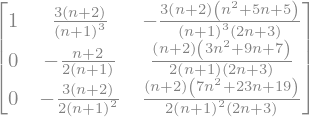

In [36]:
v = sp.Matrix([(n + 1)**2/sp.Integer(2), 3*(n + 1)/sp.Integer(2), 1])
U = sp.Matrix.hstack(v, sp.Matrix([1, 0, 0]), sp.Matrix([0, 1, 0]))

r = sp.Matrix([[
    3*(n + 2)/(n + 1)**3,
    -3*(n + 2)*(n**2 + 5*n + 5)/((n + 1)**3*(2*n + 3)),
]])
Q = sp.Matrix([
    [
        -(n + 2)/(2*(n + 1)),
        (n + 2)*(3*n**2 + 9*n + 7)/(2*(n + 1)*(2*n + 3)),
    ],
    [
        -3*(n + 2)/(2*(n + 1)**2),
        (n + 2)*(7*n**2 + 23*n + 19)/(2*(n + 1)**2*(2*n + 3)),
    ],
])

C_expected = sp.Matrix([
    [1, r[0, 0], r[0, 1]],
    [0, Q[0, 0], Q[0, 1]],
    [0, Q[1, 0], Q[1, 1]],
])

assert_zero(U.det() - 1, "det U(n)=1")
assert_matrix_zero(M*v.subs(n, n + 1) - v, "M(n)v_{n+1}=v_n")
C = exact_matrix(U.inv()*M*U.subs(n, n + 1))
assert_matrix_zero(C - C_expected, "block coboundary")

print("PASS: det U(n)=1, invariant column, and exact block form.")
display(C)


## 2. Closed form of the lower product

Let
$$
\Psi_N=Q(0)Q(1)\cdots Q(N-1),\qquad
b_m=\binom{2m}{m},\qquad c_m=\frac12b_m,
$$
$$
A_N=3\sum_{k=1}^N\frac1{k^2b_k}.
$$
The proof uses one formal matrix induction identity.


In [37]:
N = sp.symbols("N", integer=True, nonnegative=True)
Avar = sp.symbols("A")
cvar = sp.symbols("c", nonzero=True)


def lower_form(index, Aval, cnext):
    m = index + 1
    return sp.Matrix([
        [m*(1 - Aval), m**2*(Aval - 1) + 1/cnext],
        [-m*Aval, m**2*Aval + 1/cnext],
    ])

lhs = lower_form(N, Avar, cvar)*Q.subs(n, N)
A_next = Avar + sp.Rational(3, 2)/((N + 1)**2*cvar)
c_next = 2*(2*N + 3)/(N + 2)*cvar
rhs = lower_form(N + 1, A_next, c_next)

assert_matrix_zero(lhs - rhs, "lower-product induction")
assert_matrix_zero(lower_form(0, 0, 1) - sp.eye(2), "lower-product base case")
assert_zero(lower_form(N, Avar, cvar).det() - (N + 1)/cvar, "lower determinant")

# Check the scalar recurrences from the binomial definitions.
c_Np1 = sp.binomial(2*N + 2, N + 1)/2
c_Np2 = sp.binomial(2*N + 4, N + 2)/2
assert_zero(c_Np2 - 2*(2*N + 3)/(N + 2)*c_Np1, "c recurrence")
assert_zero(
    3/((N + 1)**2*sp.binomial(2*N + 2, N + 1))
    - sp.Rational(3, 2)/((N + 1)**2*c_Np1),
    "A increment",
)

print("PASS: exact lower-product induction, base case, and determinant.")


PASS: exact lower-product induction, base case, and determinant.


Thus
$$
\Psi_N=
\begin{pmatrix}
(N+1)(1-A_N)&(N+1)^2(A_N-1)+c_{N+1}^{-1}\\
-(N+1)A_N&(N+1)^2A_N+c_{N+1}^{-1}
\end{pmatrix}.
$$


## 3. Recovering the quotient

Let
$$
\Phi_N=M(0)\cdots M(N-1),\qquad
L_N=\frac{p\Phi_Ne_1}{q\Phi_Ne_1}.
$$
The block product gives the exact identities
$$
q\Phi_Ne_1=-(N+1),\qquad L_N=A_N+Z_N,
$$
where $Z_N=s_N/(2(N+1))$ and $s_N$ is the upper coordinate of the
transformed product.


In [38]:
U0 = U.subs(n, 0)
assert_matrix_zero(U.inv()*e1 - sp.Matrix([0, 1, 0]), "U(n)^{-1}e_1")
assert_matrix_zero(p*U0 - sp.Matrix([[-sp.Rational(1, 2), 0, 1]]), "pU(0)")
assert_matrix_zero(q*U0 - sp.Matrix([[0, -1, 1]]), "qU(0)")

s = sp.symbols("s")
xN = lower_form(N, Avar, cvar)[0, 0]
yN = lower_form(N, Avar, cvar)[1, 0]
assert_zero(yN - xN + (N + 1), "q Phi_N e_1=-(N+1)")
assert_zero((yN - s/2)/(yN - xN) - (Avar + s/(2*(N + 1))), "L_N=A_N+Z_N")

print("PASS: exact denominator and quotient decomposition.")


PASS: exact denominator and quotient decomposition.


## 4. Finite formula for $Z_N$

The upper-right block is a sum of suffix products.  Substituting the closed
form of $\Psi_N$ gives
$$
Z_N=\frac32\sum_{k=1}^N\frac1{k^3}
-\frac92\sum_{1\le m<k\le N}\frac{c_m}{m k^2c_k}.
$$


In [39]:
j = sp.symbols("j", integer=True, nonnegative=True)
A_jp1, A_big = sp.symbols("A_jp1 A_big")
c_jp1, c_big = sp.symbols("c_jp1 c_big", nonzero=True)
c_jp2 = 2*(2*j + 3)/(j + 2)*c_jp1

Psi_jp1 = lower_form(j + 1, A_jp1, c_jp2)
Psi_big = lower_form(N, A_big, c_big)
suffix = exact((r.subs(n, j)*Psi_jp1.inv()*Psi_big*sp.Matrix([1, 0]))[0])
target = (N + 1)*(3/(j + 1)**3 - 6*c_jp1/(j + 1)*(A_big - A_jp1))
assert_zero(suffix - target, "suffix contribution")


def c_exact(m):
    return sp.binomial(2*m, m)/2


def A_exact(Nv):
    return sp.factor(3*sum(sp.Rational(1, k**2*sp.binomial(2*k, k)) for k in range(1, Nv + 1)))


def Z_exact(Nv):
    h3 = sum(sp.Rational(1, k**3) for k in range(1, Nv + 1))
    dsum = sum(
        c_exact(m)/(m*k**2*c_exact(k))
        for m in range(1, Nv + 1)
        for k in range(m + 1, Nv + 1)
    )
    return sp.factor(sp.Rational(3, 2)*h3 - sp.Rational(9, 2)*dsum)

Pprod = sp.eye(3)
for Nv in range(1, 11):
    Pprod = exact_matrix(Pprod*C.subs(n, Nv - 1))
    assert_zero(Pprod[0, 1]/(2*(Nv + 1)) - Z_exact(Nv), f"Z_N at N={Nv}")

print("PASS: symbolic suffix identity and finite Z_N checks for N=1,...,10.")


PASS: symbolic suffix identity and finite Z_N checks for N=1,...,10.


## 5. The $\zeta(2)$ contribution

The beta integral and Tonelli's theorem give
$$
\sum_{k=1}^{\infty}\frac1{k^2\binom{2k}{k}}
=-\int_0^1\frac{\log(1-x+x^2)}x\,dx
=\frac13\zeta(2).
$$


In [40]:
assert_zero((1 - x + x**2 - (1 + x**3)/(1 + x)).factor(), "quadratic factorization")


In [41]:
k = sp.symbols("k", integer=True, positive=True)
x = sp.symbols("x", positive=True)

assert_zero(sp.expand_func(sp.beta(k, k + 1)/k) - 1/(k**2*sp.binomial(2*k, k)), "beta integral")
assert_zero((1 - x + x**2 - (1 + x**3)/(1 + x)).factor(), "quadratic factorization")
assert_zero(sp.diff(x**3, x)/(3*x**3) - 1/x, "x^3 substitution")

Iplus = sp.integrate(sp.log(1 + x)/x, (x, 0, 1))
assert not Iplus.has(sp.Integral)
assert_zero(Iplus - sp.zeta(2)/2, "log integral")
assert_zero(3*sp.Rational(2, 3)*Iplus - sp.zeta(2), "A_N limit")

print("PASS: exact zeta(2) evaluation.")


PASS: exact zeta(2) evaluation.


## 6. Reduction of the remaining double sum to one integral

For
$$
D=\sum_{1\le m<k}\frac{c_m}{m k^2c_k}
$$
we obtain
$$
D=-2\int_0^1\frac{(1-t)\log t\log(1+t)}{(1+t)(1+t+t^2)}\,dt.
$$
The next cell verifies the generating function, region boundaries,
Jacobians, and final rational prefactor exactly.


In [42]:
u, t, x, y = sp.symbols("u t x y", positive=True)
Aclosed = 2*sp.log(2/(1 + sp.sqrt(1 - 4*u)))
Atarget = (1/u)*(1/sp.sqrt(1 - 4*u) - 1)
assert_zero(sp.diff(Aclosed, u) - Atarget, "central-binomial generating function")
assert sp.limit(Aclosed, u, 0, dir="+") == 0

uminus = (1 - sp.sqrt(1 - 4*u))/2
uplus = (1 + sp.sqrt(1 - 4*u))/2
assert_zero(uminus*(1 - uminus) - u, "lower region root")
assert_zero(uplus*(1 - uplus) - u, "upper region root")

u_of_t = t/(1 + t)**2
rad = (1 - t)/(1 + t)
assert_zero(1 - 4*u_of_t - rad**2, "radical substitution")
assert_zero(sp.diff(u_of_t, t) - (1 - t)/(1 + t)**3, "Jacobian")
assert_zero(1 - u_of_t - (1 + t + t**2)/(1 + t)**2, "1-u")
assert_zero(2/(1 + rad) - (1 + t), "A(u) argument")
assert_zero((1 + rad)/(1 - rad) - 1/t, "log ratio")
assert_zero(
    2/(1 - u_of_t)*sp.diff(u_of_t, t)
    - 2*(1 - t)/((1 + t)*(1 + t + t**2)),
    "complete prefactor",
)

print("PASS: all algebraic transformations in the integral reduction.")


PASS: all algebraic transformations in the integral reduction.


## 7. Exact external integral certificate

The sole external symbolic step is
$$
-2\int_0^1\frac{(1-x)\log x\log(1+x)}{(1+x)(1+x+x^2)}\,dx
=\frac19\zeta(3).
$$

Paste this into Wolfram|Alpha or a Wolfram Language kernel:

```wolfram
FullSimplify[
  Integrate[
    -2 (1 - x) Log[x] Log[1 + x]/((1 + x) (1 + x + x^2)),
    {x, 0, 1}
  ] - Zeta[3]/9
]
```

The exact output is `0`.

[Open the exact Wolfram|Alpha verification](https://www.wolframalpha.com/input?i=FullSimplify%5BIntegrate%5B-2+%281+-+x%29+Log%5Bx%5D+Log%5B1+%2B+x%5D%2F%28%281+%2B+x%29+%281+%2B+x+%2B+x%5E2%29%29%2C+%7Bx%2C+0%2C+1%7D%5D+-+Zeta%5B3%5D%2F9%5D)


In [43]:
# The exact external certificate is now used only as the symbolic value D=zeta(3)/9.
D_closed = sp.zeta(3)/9
Z_limit = sp.Rational(3, 2)*sp.zeta(3) - sp.Rational(9, 2)*D_closed
assert_zero(Z_limit - sp.zeta(3), "Z_N limit")
assert_zero(sp.zeta(2) + Z_limit - (sp.zeta(2) + sp.zeta(3)), "L_N limit")

# Independent high-precision numerical check of the external certificate (not part of the proof).
mp.mp.dps = 60
f = lambda xx: -2*(1 - xx)*mp.log(xx)*mp.log(1 + xx)/((1 + xx)*(1 + xx + xx**2))
num_integral = mp.quad(f, [0, 1])
num_error = num_integral - mp.zeta(3)/9
print("Numerical check error:", mp.nstr(num_error, 8))
print("PASS: concluding exact algebra.")


Numerical check error: 0.0
PASS: concluding exact algebra.


## 8. Bridge to the recurrence in Question 2.6

Set
$$
L_N=A_N+Z_N.
$$
We prove that the challenge sequence is exactly
$$
u_n=L_{n+3}-L_{n+2}.
$$
The resulting explicit formula is
$$
u_n=-\frac32\frac{1}{(n+3)^2\binom{2n+5}{n+2}}
\left(\frac12+\sum_{k=0}^n
\frac{(3k+8)\binom{2k+4}{k+2}}{(k+2)(k+3)^2}\right).
$$


In [44]:
# First-difference formula for L_N, expressed with a formal prefix sum Bsum.
Bsum = sp.symbols("Bsum")
bN = sp.symbols("bN", nonzero=True)
dL_form = sp.Rational(3, 2)/N**3 + 3/(N**2*bN) - sp.Rational(9, 2)*Bsum/(N**2*bN)

# Prove the finite binomial identity used to rewrite the difference.
nn = sp.symbols("nn", integer=True, nonnegative=True)
b = lambda m: sp.binomial(2*m, m)
h = (3*nn + 8)*b(nn + 2)/((nn + 2)*(nn + 3)**2)

S0 = sp.Rational(1, 2) + 8*sp.binomial(4, 2)/(2*3**2)
R0 = -1 - b(3)/(2*3) + sp.Rational(3, 2)*(b(1)/1 + b(2)/2)
assert_zero(S0 - R0, "binomial identity base case")

R_difference = (
    -b(nn + 3)/(2*(nn + 3))
    + 2*b(nn + 2)/(nn + 2)
)
assert_zero(R_difference - h, "binomial identity first difference")

# Verify that the rewritten first difference is the claimed u_n formula.
Ssym = sp.symbols("S")
N_as_n = nn + 3
bN_as_n = b(nn + 3)
Bsum_from_S = sp.Rational(2, 3)*(Ssym + 1 + bN_as_n/(2*N_as_n))
rewritten = dL_form.subs({N: N_as_n, bN: bN_as_n, Bsum: Bsum_from_S})
target_u = -3*Ssym/(N_as_n**2*bN_as_n)
assert_zero(rewritten - target_u, "L difference to explicit u_n")
assert_zero(b(nn + 3) - 2*sp.binomial(2*nn + 5, nn + 2), "central-binomial conversion")

print("PASS: exact bridge from L_{n+3}-L_{n+2} to the explicit u_n formula.")


PASS: exact bridge from L_{n+3}-L_{n+2} to the explicit u_n formula.


### Initial values and recurrence

Let
$$
S_n=\frac12+\sum_{k=0}^n h_k,
\qquad
h_n=\frac{(3n+8)\binom{2n+4}{n+2}}{(n+2)(n+3)^2}.
$$
The recurrence check reduces to two elementary ratios and one polynomial identity.


In [45]:
def S_exact(nv):
    return sp.Rational(1, 2) + sum(
        (3*k + 8)*sp.binomial(2*k + 4, k + 2)/((k + 2)*(k + 3)**2)
        for k in range(nv + 1)
    )


def u_closed(nv):
    return sp.factor(
        -sp.Rational(3, 2)*S_exact(nv)
        /((nv + 3)**2*sp.binomial(2*nv + 5, nv + 2))
    )

assert_zero(u_closed(1) + sp.Rational(93, 4480), "u_1")
assert_zero(u_closed(2) + sp.Rational(117, 14000), "u_2")

nrec = sp.symbols("nrec", integer=True, positive=True)
Brec = sp.binomial(2*nrec + 5, nrec + 2)
Bprev = sp.binomial(2*nrec + 3, nrec + 1)
hrec = (3*nrec + 8)*sp.binomial(2*nrec + 4, nrec + 2)/((nrec + 2)*(nrec + 3)**2)
hprev = (3*nrec + 5)*sp.binomial(2*nrec + 2, nrec + 1)/((nrec + 1)*(nrec + 2)**2)

assert_zero(Brec/Bprev - 2*(2*nrec + 5)/(nrec + 3), "B_n/B_{n-1}")
assert_zero(
    hrec/hprev
    - 2*(nrec + 1)*(2*nrec + 3)*(3*nrec + 8)/((nrec + 3)**2*(3*nrec + 5)),
    "h_n/h_{n-1}",
)

Ppoly = 15*nrec**3 + 85*nrec**2 + 155*nrec + 93
assert_zero((
    Ppoly
    - (nrec + 3)**2*(3*nrec + 5)
    - 2*(nrec + 1)*(2*nrec + 3)*(3*nrec + 8)).factor(),
    "coefficient decomposition",
)

S_nm2 = sp.symbols("S_nm2")
reduced = (
    (nrec + 3)**2*(3*nrec + 5)*(S_nm2 + hprev + hrec)
    - Ppoly*(S_nm2 + hprev)
    + 2*(nrec + 1)*(2*nrec + 3)*(3*nrec + 8)*S_nm2
)
assert_zero(reduced, "reduced recurrence")

# Direct finite check against the original recurrence for additional assurance.
for nv in range(3, 18):
    recurrence_value = (
        -2*(nv + 3)**3*(2*nv + 5)*(3*nv + 5)*u_closed(nv)
        + (nv + 2)**2*(15*nv**3 + 85*nv**2 + 155*nv + 93)*u_closed(nv - 1)
        - (nv + 1)**3*(nv + 2)*(3*nv + 8)*u_closed(nv - 2)
    )
    assert_zero(recurrence_value, f"direct recurrence n={nv}")

print("PASS: initial values and exact recurrence.")


PASS: initial values and exact recurrence.


## 9. Exact telescoping and final verification

We verify
$$
L_3=\frac{2077}{720},
\qquad
\frac{2077}{720}+\sum_{n=1}^{N}u_n=L_{N+3}.
$$


In [46]:
# Compute exact L_N from both the matrix product and the finite formulas.
Phi = sp.eye(3)
L_matrix = []
for Nv in range(0, 14):
    if Nv > 0:
        Phi = exact_matrix(Phi*M.subs(n, Nv - 1))
    numerator = exact((p*Phi*e1)[0])
    denominator = exact((q*Phi*e1)[0])
    assert_zero(denominator + (Nv + 1), f"denominator N={Nv}")
    L_matrix.append(exact(numerator/denominator))

assert_zero(L_matrix[3] - sp.Rational(2077, 720), "L_3")
for nv in range(1, 10):
    assert_zero(L_matrix[nv + 3] - L_matrix[nv + 2] - u_closed(nv), f"u_n increment n={nv}")
    assert_zero(
        sp.Rational(2077, 720) + sum(u_closed(jj) for jj in range(1, nv + 1)) - L_matrix[nv + 3],
        f"telescoping N={nv}",
    )

print("PASS: L_3, increment identity, and telescoping partial sums.")


PASS: L_3, increment identity, and telescoping partial sums.


## 10. Numerical sanity check (not part of the proof)


In [47]:
mp.mp.dps = 50
target = mp.zeta(2) + mp.zeta(3)
partial = mp.mpf(2077)/720
rows = []
for nv in range(1, 21):
    partial += mp.mpf(str(sp.N(u_closed(nv), 60)))
    if nv in {1, 2, 3, 5, 10, 20}:
        rows.append((nv, mp.nstr(partial, 25), mp.nstr(partial - target, 8)))

for row in rows:
    print(f"N={row[0]:2d}  partial={row[1]}  error={row[2]}")


N= 1  partial=2.863963293650793650793651  error=0.016972324
N= 2  partial=2.855606150793650793650794  error=0.0086151808
N= 3  partial=2.851876893939393939393939  error=0.0048859239
N= 5  partial=2.848996627681417222233549  error=0.0020056577
N=10  partial=2.847449699773243481357188  error=0.00045872977
N=20  partial=2.847073338797563983784021  error=8.236879e-5


## Conclusion

All finite algebraic claims, including the missing bridge to the recurrence in
Question 2.6, have been verified exactly.  Conditional only on the displayed
Wolfram|Alpha integral certificate,
$$
\frac{2077}{720}+\sum_{n=1}^{\infty}u_n=\zeta(2)+\zeta(3).
$$
